In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn xgboost gradio ipykernel


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Run the cell above once (it installs every library used below). In VS Code, if a library was newly installed, **restart the kernel** once and run the notebook from the top.

# Customer Churn Prediction: Classification Models

**Goal:** Predict whether a telecom customer will leave (`Churn = Yes`) or stay (`Churn = No`).

**Flow of this notebook**
1. Load data and run EDA (plots)
2. Handle missing values
3. Encoding and Standard Scaling
4. Train and test 7 classification algorithms one by one
5. Compare all models

## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from matplotlib.colors import ListedColormap
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

sns.set_style("whitegrid")

## 2. Load the Data

In [3]:
df = pd.read_csv("customer_churn.csv")
df.head()

,CustomerID,Gender,Age,SeniorCitizen,City,Partner,Dependents,Contract,Tenure,PhoneService,...,OnlineSecurity,TechSupport,StreamingTV,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,NumSupportCalls,DataUsageGB,Churn
0,CUST-10000,Male,46.0,0,Delhi,Yes,No,One year,72.0,Yes,...,No internet service,No internet service,No internet service,No,Mailed check,229.42,16726.30,2.0,0.0,No
1,CUST-10001,Female,62.0,1,Hyderabad,Yes,Yes,Month-to-month,36.0,Yes,...,No internet service,No internet service,No internet service,Yes,Mailed check,445.72,15822.31,1.0,0.0,No
2,CUST-10002,Female,44.0,0,NaN,Yes,No,Two year,72.0,Yes,...,No,Yes,No,No,Bank transfer,968.79,72869.82,3.0,28.4,No
3,CUST-10003,Male,42.0,0,Mumbai,Yes,No,Two year,21.0,Yes,...,No,No,No,No,Bank transfer,1103.98,22773.16,1.0,67.4,No
4,CUST-10004,Male,60.0,1,Mumbai,No,No,Month-to-month,3.0,Yes,...,No,Yes,Yes,Yes,Electronic check,1000.29,2897.93,2.0,42.5,No


In [4]:
df.shape

(7000, 22)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        7000 non-null   str    
 1   Gender            6930 non-null   str    
 2   Age               6720 non-null   float64
 3   SeniorCitizen     7000 non-null   int64  
 4   City              6755 non-null   str    
 5   Partner           7000 non-null   str    
 6   Dependents        7000 non-null   str    
 7   Contract          6930 non-null   str    
 8   Tenure            6860 non-null   float64
 9   PhoneService      7000 non-null   str    
 10  MultipleLines     7000 non-null   str    
 11  InternetService   7000 non-null   str    
 12  OnlineSecurity    7000 non-null   str    
 13  TechSupport       7000 non-null   str    
 14  StreamingTV       7000 non-null   str    
 15  PaperlessBilling  7000 non-null   str    
 16  PaymentMethod     6825 non-null   str    
 17  Monthl

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,6720.0,44.111905,14.524081,18.0,34.0000,44.000,54.0000,85.00
SeniorCitizen,7000.0,0.153286,0.360288,0.0,0.0000,0.000,0.0000,1.00
Tenure,6860.0,31.354082,22.742622,0.0,12.0000,25.000,48.0000,72.00
MonthlyCharges,6860.0,942.366345,338.980476,150.0,764.4750,1027.225,1195.2950,1615.75
TotalCharges,6790.0,29634.327912,25261.738332,0.0,9698.3075,21194.895,43207.3325,116919.87
NumSupportCalls,6790.0,1.951546,1.516010,0.0,1.0000,2.000,3.0000,10.00
DataUsageGB,7000.0,101.366829,87.542008,0.0,33.2750,88.900,149.8000,694.10


## 3. Exploratory Data Analysis (EDA)

### 3.1 Missing values

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

Age                280
City               245
TotalCharges       210
NumSupportCalls    210
PaymentMethod      175
MonthlyCharges     140
Tenure             140
Gender              70
Contract            70
dtype: int64

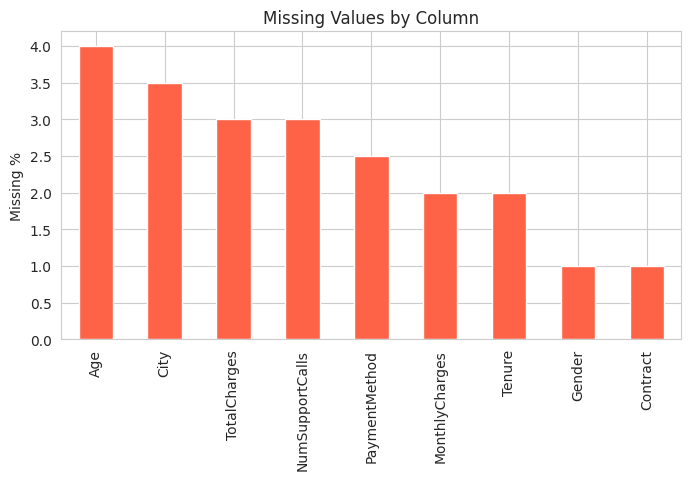

In [8]:
(missing / len(df) * 100).plot(kind="bar", color="tomato", figsize=(8, 4))
plt.ylabel("Missing %")
plt.title("Missing Values by Column")
plt.show()

### 3.2 Target variable: how many customers churn?

In [9]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     71.942857
Yes    28.057143
Name: proportion, dtype: float64

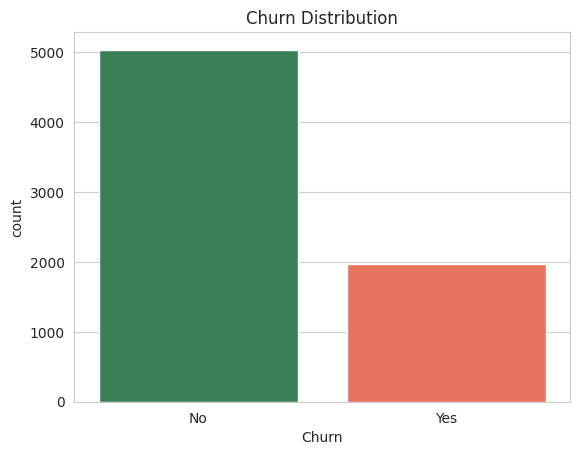

In [10]:
sns.countplot(x="Churn", data=df, palette=["seagreen", "tomato"])
plt.title("Churn Distribution")
plt.show()

The data is **imbalanced** (more customers stay than leave). So accuracy alone can be misleading, and we will also look at recall and F1-score at the end.

### 3.3 Distribution of numeric columns

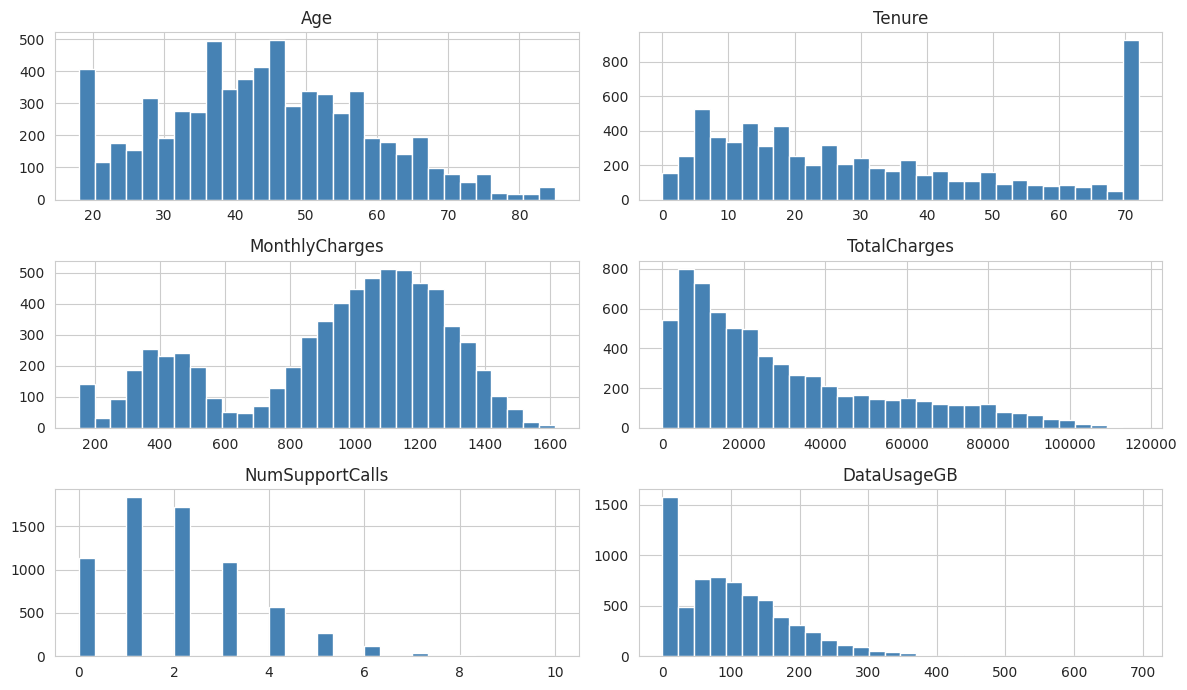

In [11]:
num_cols = ["Age", "Tenure", "MonthlyCharges", "TotalCharges", "NumSupportCalls", "DataUsageGB"]
df[num_cols].hist(bins=30, figsize=(12, 7), color="steelblue")
plt.tight_layout()
plt.show()

### 3.4 Numeric columns vs Churn (boxplots)

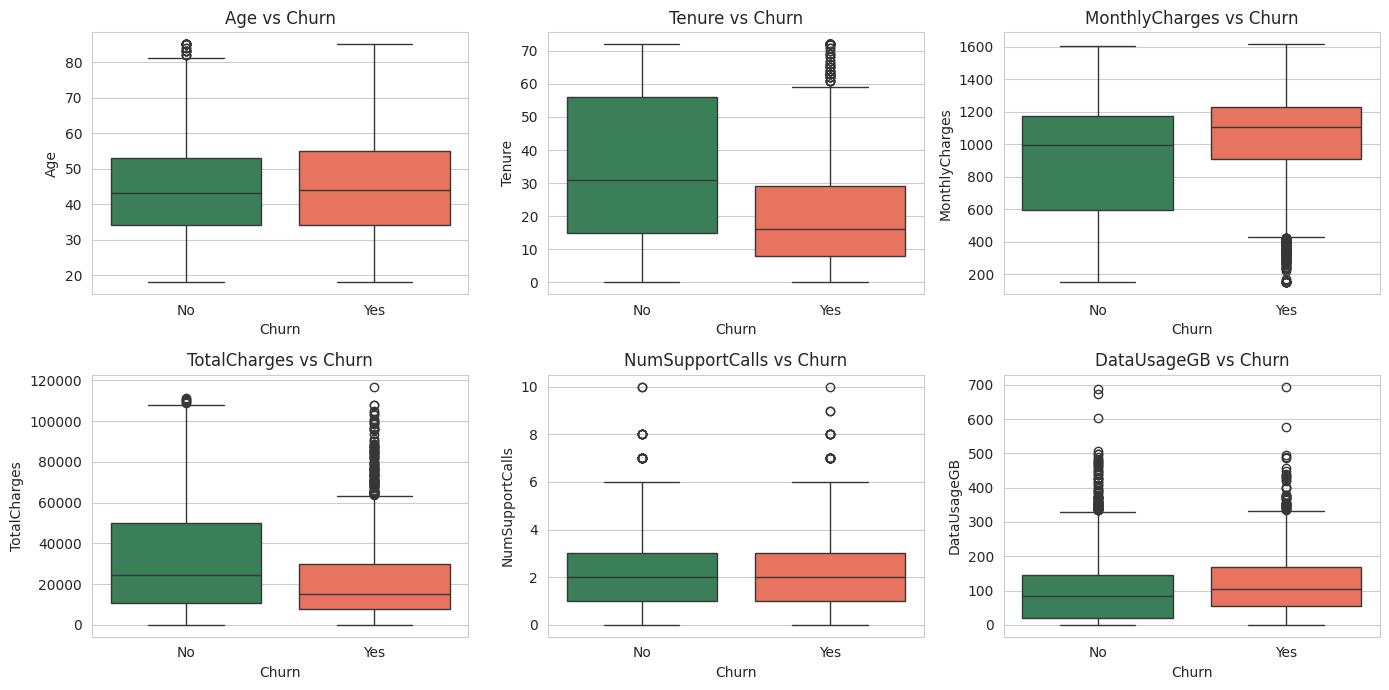

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Churn", y=col, data=df, ax=ax, palette=["seagreen", "tomato"])
    ax.set_title(f"{col} vs Churn")
plt.tight_layout()
plt.show()

**Observation:** Churned customers usually have a lower tenure and make more support calls.

### 3.5 Categorical columns vs Churn

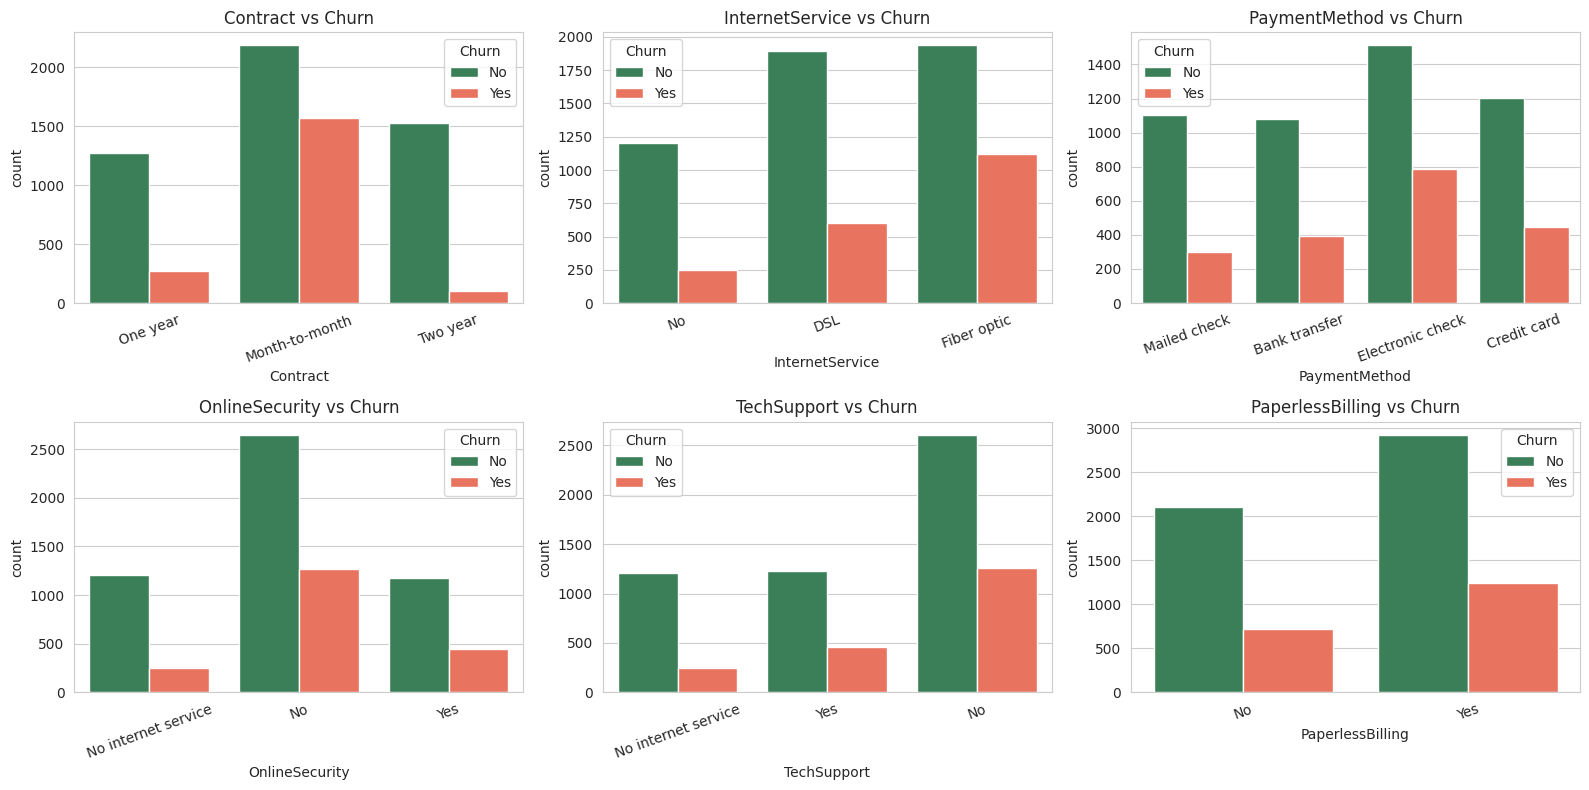

In [13]:
cat_plot = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity", "TechSupport", "PaperlessBilling"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cat_plot):
    sns.countplot(x=col, hue="Churn", data=df, ax=ax, palette=["seagreen", "tomato"])
    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 3.6 Churn rate by group

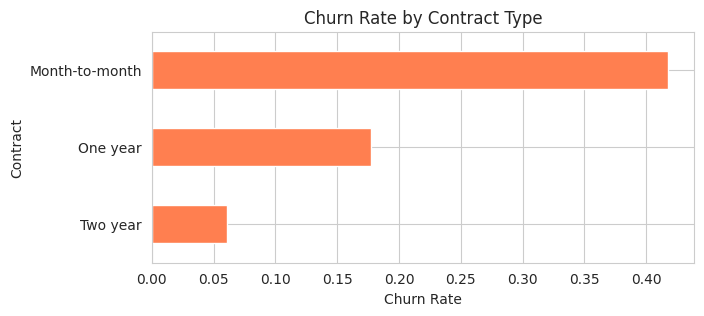

In [14]:
churn_flag = (df["Churn"] == "Yes").astype(int)
churn_flag.groupby(df["Contract"]).mean().sort_values().plot(kind="barh", color="coral", figsize=(7, 3))
plt.xlabel("Churn Rate")
plt.title("Churn Rate by Contract Type")
plt.show()

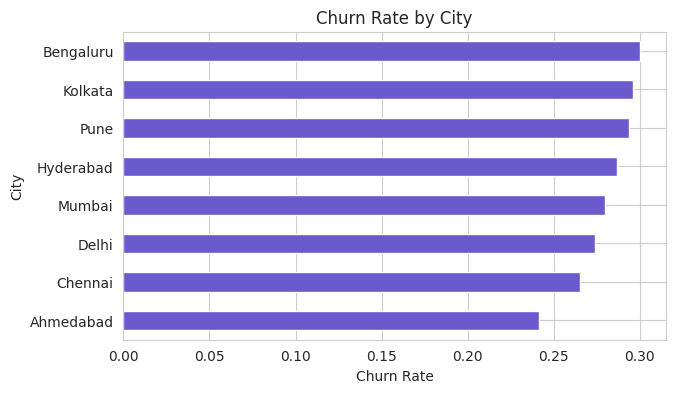

In [15]:
churn_flag.groupby(df["City"]).mean().sort_values().plot(kind="barh", color="slateblue", figsize=(7, 4))
plt.xlabel("Churn Rate")
plt.title("Churn Rate by City")
plt.show()

### 3.7 Tenure and charges

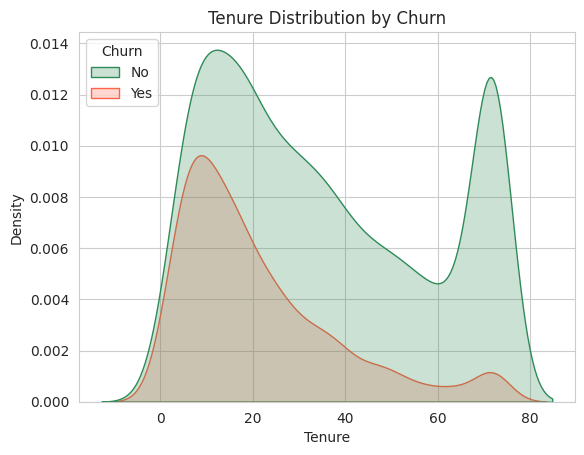

In [16]:
sns.kdeplot(data=df, x="Tenure", hue="Churn", fill=True, palette=["seagreen", "tomato"])
plt.title("Tenure Distribution by Churn")
plt.show()

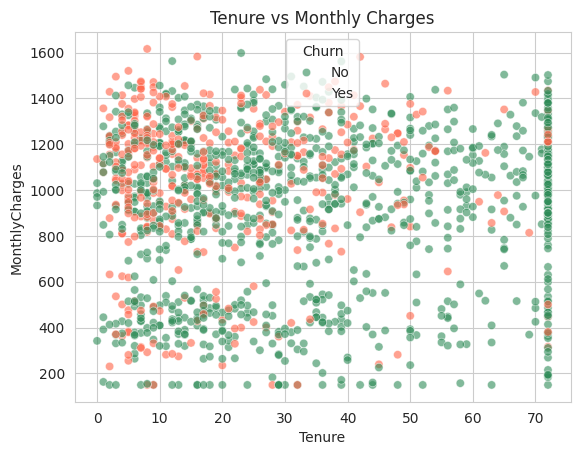

In [17]:
sns.scatterplot(x="Tenure", y="MonthlyCharges", hue="Churn", data=df.sample(1500, random_state=1), palette=["seagreen", "tomato"], alpha=0.6)
plt.title("Tenure vs Monthly Charges")
plt.show()

### 3.8 Correlation heatmap

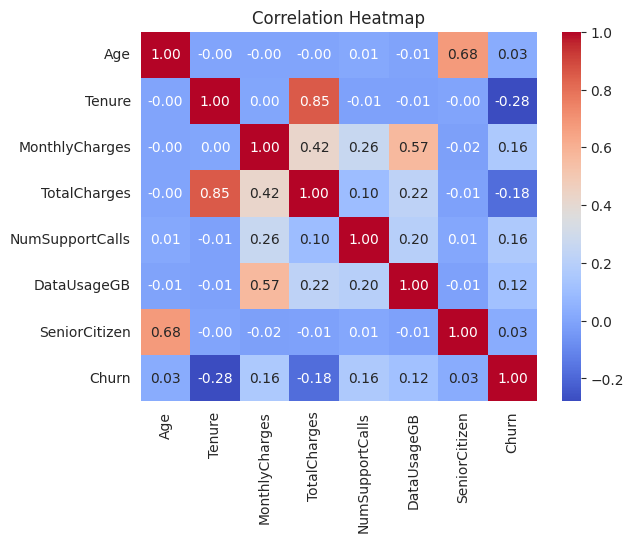

In [18]:
corr_df = df[num_cols + ["SeniorCitizen"]].copy()
corr_df["Churn"] = churn_flag
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## 4. Data Cleaning and Preprocessing

Steps:
1. Drop `CustomerID` (just an ID, no predictive value)
2. Convert target `Churn` to 0 and 1
3. Split into train and test **before** filling missing values (so the test data does not leak into training)
4. Fill missing values: median for numeric, mode for categorical
5. One-hot encoding for categorical columns
6. Standard Scaling for numeric columns

In [19]:
df = df.drop(columns=["CustomerID"])
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### 4.1 Handle missing values

In [20]:
num_cols = ["Age", "Tenure", "MonthlyCharges", "TotalCharges", "NumSupportCalls", "DataUsageGB"]
cat_cols = X_train.select_dtypes(include="object").columns.tolist()

for col in num_cols:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

for col in cat_cols:
    mode = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode)
    X_test[col] = X_test[col].fillna(mode)

X_train.isnull().sum().sum() + X_test.isnull().sum().sum()

np.int64(0)

### 4.2 Encoding (One-Hot)

In [21]:
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train = X_train.astype(float)
X_test = X_test.astype(float)
feature_cols = X_train.columns.tolist()
X_train.shape

(5600, 34)

### 4.3 Standard Scaling

In [22]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train.head()

,Age,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,NumSupportCalls,DataUsageGB,Gender_Male,City_Bengaluru,City_Chennai,...,OnlineSecurity_No internet service,OnlineSecurity_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,PaperlessBilling_Yes,PaymentMethod_Credit card,PaymentMethod_Electronic check,PaymentMethod_Mailed check
1561,-0.772196,0.0,0.484057,-0.456910,0.107499,-1.306140,1.616610,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
5345,-0.702011,0.0,0.173637,1.379980,0.710360,-0.639985,-0.413624,1.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
4389,0.420946,0.0,-0.535894,0.424992,-0.318475,0.026170,0.846561,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4928,-1.684598,0.0,1.370971,0.360954,1.459623,2.024636,0.268452,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3590,-0.351087,0.0,-0.358511,0.131864,-0.241411,-1.306140,-0.659263,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0


## 5. Model Building

### 5.1 Understanding the Confusion Matrix (read this before the models)

Accuracy is only one number. The **confusion matrix** shows *where* the model is right and *where* it is wrong. 
In this project the **positive class is Churn** (the thing we want to catch).

| | **Predicted: Stay** | **Predicted: Churn** |
|---|---|---|
| **Actual: Stay** | **TN** (True Negative) | **FP** (False Positive) |
| **Actual: Churn** | **FN** (False Negative) | **TP** (True Positive) |

**Easy way to remember:** the 2nd word is what the *model predicted* (Positive = Churn, Negative = Stay), and the 1st word tells if the model was *right* (True) or *wrong* (False).

| Box | What happened | Good or bad? | Business meaning |
|---|---|---|---|
| **TN** | Customer stays, model says Stay | Good (we want it HIGH) | No action needed, correct |
| **TP** | Customer leaves, model says Churn | Good (we want it HIGH) | We can contact the customer and save them |
| **FP** | Customer stays, model says Churn | Bad (we want it LOW) | False alarm. We waste a discount or a call |
| **FN** | Customer leaves, model says Stay | Worst (we want it as LOW as possible) | We miss the churner and lose the customer and revenue |

**So which boxes do we want?**
- The **diagonal (TN and TP)** should have big numbers. These are the correct predictions (green boxes in the plots).
- **FP and FN** should be small. These are the mistakes (red boxes in the plots).
- In churn prediction, **FN is the most costly mistake**, so a good model has a high **TP** and a low **FN** (high Recall) while keeping FP reasonable.

**Metrics built from these four boxes**

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / Total | Overall, how often is the model right? |
| Precision | TP / (TP + FP) | When the model says Churn, how often is it correct? |
| Recall (Sensitivity) | TP / (TP + FN) | Out of all real churners, how many did we catch? |
| Specificity | TN / (TN + FP) | Out of all loyal customers, how many did we correctly leave alone? |
| F1-Score | 2 x (Precision x Recall) / (Precision + Recall) | Balance between Precision and Recall |

A helper function now trains each model, draws a **labeled confusion matrix**, explains TN, FP, FN and TP in plain words with a verdict, and saves the scores for the final comparison.

In [23]:
results = {}
cm_store = {}

def show_confusion_matrix(name, cm):
    labels = [["TN", "FP"], ["FN", "TP"]]
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f4b6b0", "#b7e1b9"]))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{cm[i, j]}", ha="center", va="center", fontsize=16, fontweight="bold")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Predicted Stay", "Predicted Churn"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Actual Stay", "Actual Churn"])
    ax.set_title(f"{name}: Confusion Matrix\n(green = correct, red = mistakes)")
    plt.show()

def explain(cm):
    tn, fp, fn, tp = cm.ravel()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    if recall >= 0.70:
        verdict = "Good. The model catches most of the customers who really leave."
    elif recall >= 0.50:
        verdict = "Average. It catches about half of the churners, so there is room to improve."
    else:
        verdict = "Needs improvement. It misses more than half of the customers who really leave (too many FN)."
    lines = [
        "| Box | Meaning | Count |",
        "|---|---|---|",
        f"| **TN** (True Negative) | Customer stays and model said Stay. Correct | {tn} |",
        f"| **FP** (False Positive) | Customer stays but model said Churn. False alarm | {fp} |",
        f"| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | {fn} |",
        f"| **TP** (True Positive) | Customer leaves and model said Churn. Correct | {tp} |",
        "",
        f"- Out of **{tp + fn}** customers who really churned, the model caught **{tp}** (Recall = {recall:.0%}) and missed **{fn}**.",
        f"- Out of **{tp + fp}** customers the model flagged as churn, **{tp}** were real churners (Precision = {precision:.0%}).",
        f"- **Verdict:** {verdict}",
    ]
    display(Markdown("\n".join(lines)))

def evaluate(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    cm_store[name] = dict(zip(["TN", "FP", "FN", "TP"], cm.ravel()))
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    }
    show_confusion_matrix(name, cm)
    explain(cm)
    return pd.Series(results[name]).round(4)

---
## Model 1: Logistic Regression

**How it works**
- Despite the name, it is a **classification** algorithm.
- It calculates a weighted sum of the features, then passes it through the **sigmoid function** to get a probability between 0 and 1.
- If the probability is greater than 0.5, the customer is predicted as `Churn`, otherwise `Stay`.
- Weights are learned by minimizing the log loss.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `C` | Inverse of regularization strength. Smaller value means stronger regularization |
| `penalty` | Type of regularization (`l1`, `l2`) |
| `solver` | Optimization algorithm (`lbfgs`, `liblinear`, `saga`) |
| `max_iter` | Maximum iterations to converge |
| `class_weight` | Use `balanced` to handle imbalanced classes |

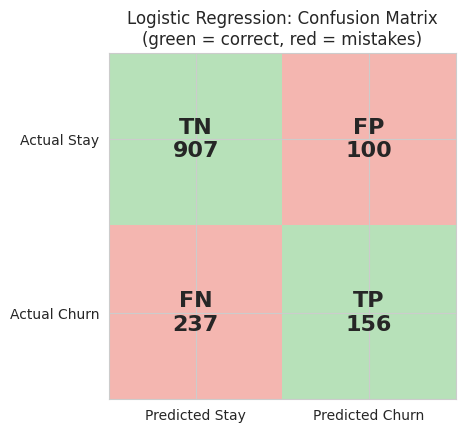

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 907 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 100 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 237 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 156 |

- Out of **393** customers who really churned, the model caught **156** (Recall = 40%) and missed **237**.
- Out of **256** customers the model flagged as churn, **156** were real churners (Precision = 61%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7593
Precision    0.6094
Recall       0.3969
F1-Score     0.4807
dtype: float64

In [24]:
lr = LogisticRegression(C=1.0, penalty="l2", solver="lbfgs", max_iter=1000)
evaluate("Logistic Regression", lr)

---
## Model 2: K-Nearest Neighbors (KNN)

**How it works**
- KNN does not really "learn". It memorizes the training data.
- For a new customer, it finds the **K closest customers** (using distance, usually Euclidean).
- The majority class among those K neighbors becomes the prediction.
- It is distance based, so **scaling is a must** (we already did it).

**Important parameters**

| Parameter | Meaning |
|---|---|
| `n_neighbors` | Number of neighbors (K). Small K can overfit, large K can underfit |
| `weights` | `uniform` (all equal) or `distance` (closer neighbors have more vote) |
| `metric` | Distance type (`minkowski`, `euclidean`, `manhattan`) |
| `p` | Power for Minkowski distance (1 = Manhattan, 2 = Euclidean) |

Let us first find a good value of K with a simple loop.

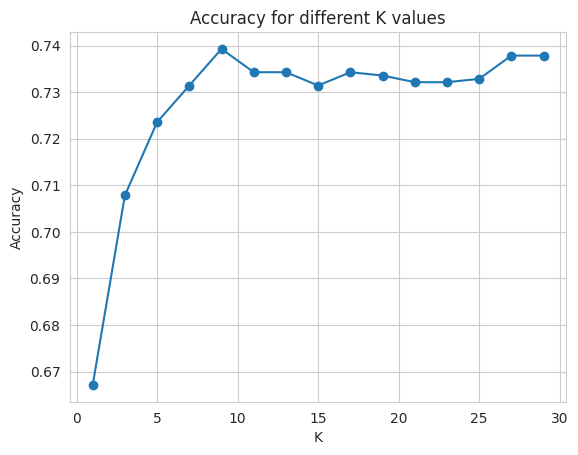

In [25]:
k_range = range(1, 31, 2)
k_scores = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_test, y_test) for k in k_range]

plt.plot(k_range, k_scores, marker="o")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title("Accuracy for different K values")
plt.show()

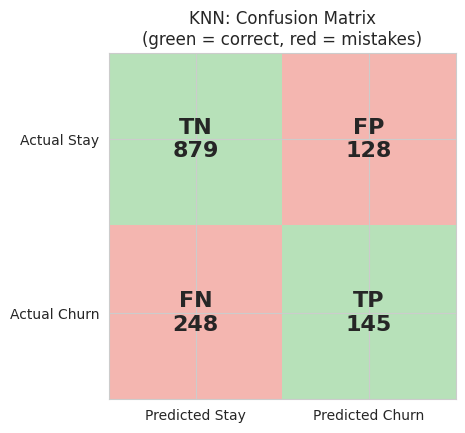

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 879 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 128 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 248 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 145 |

- Out of **393** customers who really churned, the model caught **145** (Recall = 37%) and missed **248**.
- Out of **273** customers the model flagged as churn, **145** were real churners (Precision = 53%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7314
Precision    0.5311
Recall       0.3690
F1-Score     0.4354
dtype: float64

In [26]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance", metric="minkowski", p=2)
evaluate("KNN", knn)

---
## Model 3: Support Vector Machine (SVM)

**How it works**
- SVM finds the **best boundary (hyperplane)** that separates the two classes with the **maximum margin**.
- The points closest to the boundary are called **support vectors**.
- With a **kernel** (like RBF), it can draw curved boundaries by mapping data into a higher dimension.
- Needs scaled data.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `C` | Penalty for misclassification. High C means a narrow margin and more risk of overfitting |
| `kernel` | `linear`, `rbf`, `poly`, `sigmoid` |
| `gamma` | Reach of a single training point (for `rbf`). High gamma means more complex boundary |
| `class_weight` | `balanced` helps with imbalance |

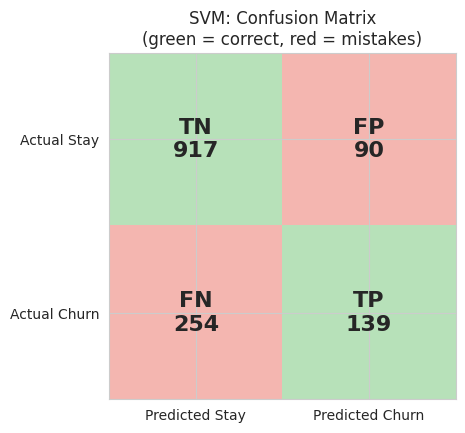

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 917 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 90 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 254 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 139 |

- Out of **393** customers who really churned, the model caught **139** (Recall = 35%) and missed **254**.
- Out of **229** customers the model flagged as churn, **139** were real churners (Precision = 61%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7543
Precision    0.6070
Recall       0.3537
F1-Score     0.4469
dtype: float64

In [27]:
svm = SVC(C=1.0, kernel="rbf", gamma="scale")
evaluate("SVM", svm)

---
## Model 4: Decision Tree

**How it works**
- It asks a series of **yes/no questions** on features (for example, "Is Tenure less than 12?").
- Each split is chosen to make the groups as **pure** as possible, using **Gini impurity** or **Entropy**.
- It keeps splitting until it reaches a leaf node, which gives the final class.
- Easy to understand, but a deep tree can **overfit**.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `criterion` | `gini` or `entropy` |
| `max_depth` | Maximum depth of the tree. Main control against overfitting |
| `min_samples_split` | Minimum samples needed to split a node |
| `min_samples_leaf` | Minimum samples required in a leaf |
| `max_features` | Number of features to consider at each split |

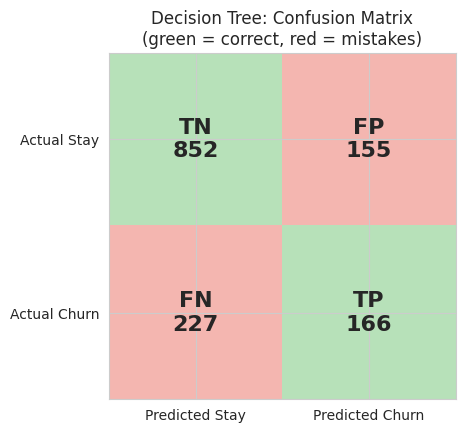

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 852 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 155 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 227 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 166 |

- Out of **393** customers who really churned, the model caught **166** (Recall = 42%) and missed **227**.
- Out of **321** customers the model flagged as churn, **166** were real churners (Precision = 52%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7271
Precision    0.5171
Recall       0.4224
F1-Score     0.4650
dtype: float64

In [28]:
dt = DecisionTreeClassifier(criterion="gini", max_depth=5, min_samples_split=20, min_samples_leaf=10, random_state=42)
evaluate("Decision Tree", dt)

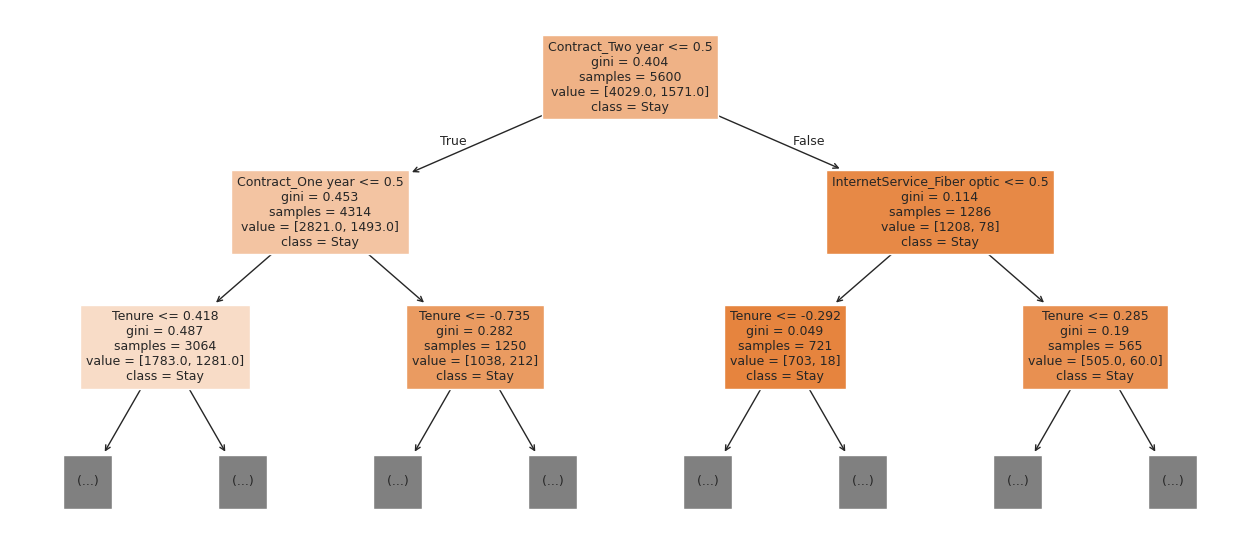

In [29]:
plt.figure(figsize=(16, 7))
plot_tree(dt, max_depth=2, feature_names=X_train.columns, class_names=["Stay", "Churn"], filled=True, fontsize=9)
plt.show()

---
## Model 5: Random Forest

**How it works**
- It builds **many decision trees**, each on a random sample of rows (bootstrap) and a random subset of features.
- Each tree votes, and the **majority vote** is the final prediction.
- This technique is called **Bagging**. It reduces overfitting compared to a single tree.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of trees |
| `max_depth` | Maximum depth of each tree |
| `max_features` | Features considered per split (`sqrt` is the default) |
| `min_samples_leaf` | Minimum samples in a leaf |
| `bootstrap` | Whether to sample rows with replacement |
| `class_weight` | Handle imbalanced data |

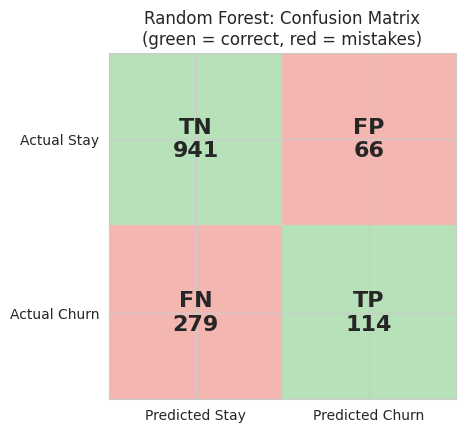

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 941 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 66 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 279 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 114 |

- Out of **393** customers who really churned, the model caught **114** (Recall = 29%) and missed **279**.
- Out of **180** customers the model flagged as churn, **114** were real churners (Precision = 63%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7536
Precision    0.6333
Recall       0.2901
F1-Score     0.3979
dtype: float64

In [30]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, max_features="sqrt", random_state=42, n_jobs=-1)
evaluate("Random Forest", rf)

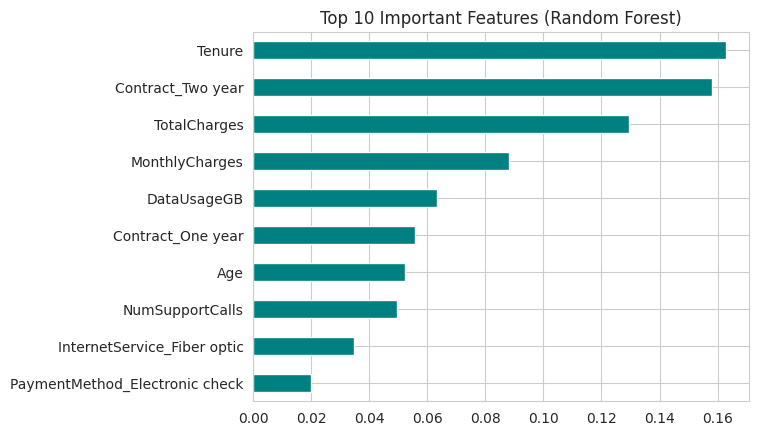

In [31]:
pd.Series(rf.feature_importances_, index=X_train.columns).nlargest(10).sort_values().plot(kind="barh", color="teal")
plt.title("Top 10 Important Features (Random Forest)")
plt.show()

---
## Model 6: AdaBoost

**How it works**
- AdaBoost is a **Boosting** technique: models are built **one after another**, not in parallel.
- It starts with a weak model (a shallow tree called a **stump**).
- Wrongly predicted rows get **higher weights**, so the next model focuses on those mistakes.
- Final prediction is a **weighted vote** of all the weak models.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `estimator` | The weak learner (default is a tree with depth 1) |
| `n_estimators` | Number of weak learners |
| `learning_rate` | How much each learner contributes. Lower value needs more estimators |

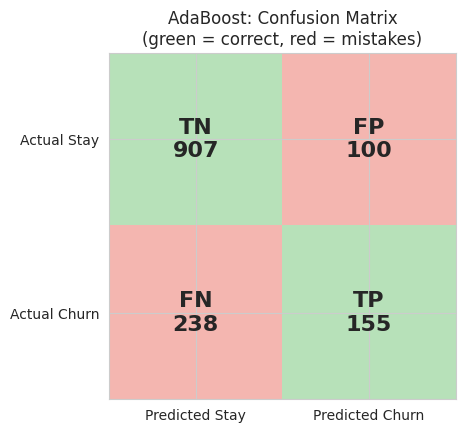

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 907 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 100 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 238 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 155 |

- Out of **393** customers who really churned, the model caught **155** (Recall = 39%) and missed **238**.
- Out of **255** customers the model flagged as churn, **155** were real churners (Precision = 61%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7586
Precision    0.6078
Recall       0.3944
F1-Score     0.4784
dtype: float64

In [32]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=200, learning_rate=0.5, random_state=42)
evaluate("AdaBoost", ada)

---
## Model 7: XGBoost

**How it works**
- XGBoost (Extreme Gradient Boosting) also builds trees **sequentially**.
- Each new tree tries to correct the **errors (residuals)** of the previous trees using gradient descent.
- It includes **regularization**, handles missing values, and is highly optimized, so it is very popular for tabular data.

**Important parameters**

| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of boosting rounds (trees) |
| `learning_rate` | Step size shrinkage. Lower value is safer but needs more trees |
| `max_depth` | Depth of each tree |
| `subsample` | Fraction of rows used for each tree |
| `colsample_bytree` | Fraction of features used for each tree |
| `gamma` | Minimum loss reduction needed to make a split |
| `reg_lambda` / `reg_alpha` | L2 / L1 regularization |
| `scale_pos_weight` | Helps with imbalanced classes |

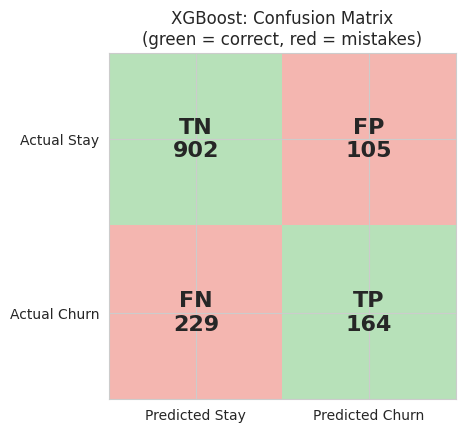

| Box | Meaning | Count |
|---|---|---|
| **TN** (True Negative) | Customer stays and model said Stay. Correct | 902 |
| **FP** (False Positive) | Customer stays but model said Churn. False alarm | 105 |
| **FN** (False Negative) | Customer leaves but model said Stay. Missed churner | 229 |
| **TP** (True Positive) | Customer leaves and model said Churn. Correct | 164 |

- Out of **393** customers who really churned, the model caught **164** (Recall = 42%) and missed **229**.
- Out of **269** customers the model flagged as churn, **164** were real churners (Precision = 61%).
- **Verdict:** Needs improvement. It misses more than half of the customers who really leave (too many FN).

Accuracy     0.7614
Precision    0.6097
Recall       0.4173
F1-Score     0.4955
dtype: float64

In [33]:
xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, reg_lambda=1, random_state=42, eval_metric="logloss")
evaluate("XGBoost", xgb)

## 6. Compare All Models

In [34]:
results_df = pd.DataFrame(results).T.round(4).sort_values("Accuracy", ascending=False)
results_df

,Accuracy,Precision,Recall,F1-Score
XGBoost,0.7614,0.6097,0.4173,0.4955
Logistic Regression,0.7593,0.6094,0.3969,0.4807
AdaBoost,0.7586,0.6078,0.3944,0.4784
SVM,0.7543,0.6070,0.3537,0.4469
Random Forest,0.7536,0.6333,0.2901,0.3979
KNN,0.7314,0.5311,0.3690,0.4354
Decision Tree,0.7271,0.5171,0.4224,0.4650


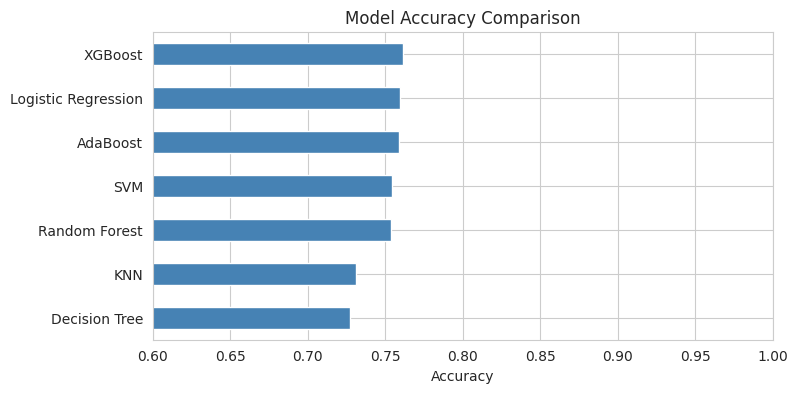

In [35]:
results_df["Accuracy"].sort_values().plot(kind="barh", color="steelblue", figsize=(8, 4))
plt.xlim(0.6, 1.0)
plt.xlabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.show()

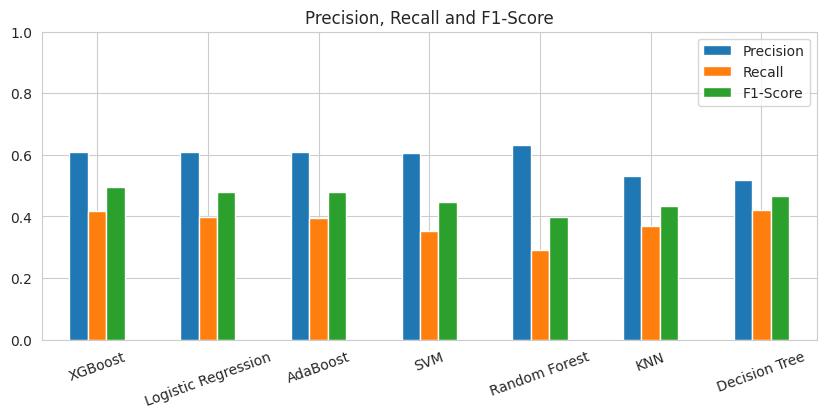

In [36]:
results_df[["Precision", "Recall", "F1-Score"]].plot(kind="bar", figsize=(10, 4))
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.title("Precision, Recall and F1-Score")
plt.show()

### Confusion matrix counts of all models

Best model = **high TN and TP**, **low FP and especially low FN**.

In [37]:
cm_df = pd.DataFrame(cm_store).T.loc[results_df.index]
cm_df

,TN,FP,FN,TP
XGBoost,902,105,229,164
Logistic Regression,907,100,237,156
AdaBoost,907,100,238,155
SVM,917,90,254,139
Random Forest,941,66,279,114
KNN,879,128,248,145
Decision Tree,852,155,227,166


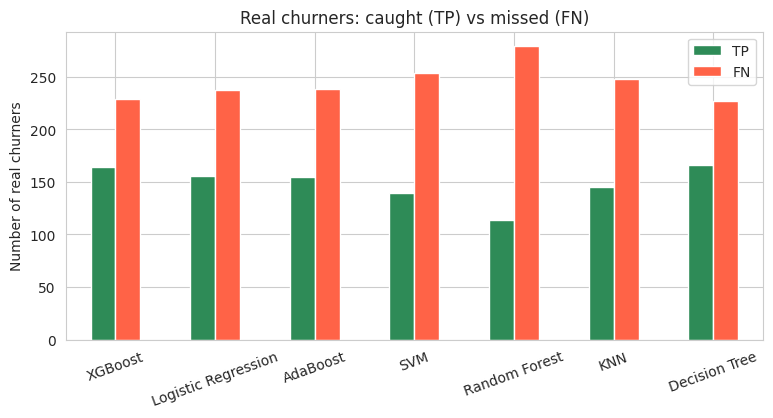

In [38]:
cm_df[["TP", "FN"]].plot(kind="bar", figsize=(9, 4), color=["seagreen", "tomato"])
plt.xticks(rotation=20)
plt.ylabel("Number of real churners")
plt.title("Real churners: caught (TP) vs missed (FN)")
plt.show()

## 7. Gradio App: Try the Best Model Live

Now we put the **best model** (highest accuracy from the table above) behind a simple web UI. 
The app takes raw customer details, applies the same preprocessing (encoding and scaling) and shows the churn probability.

In [39]:
import gradio as gr

models = {
    "Logistic Regression": lr, "KNN": knn, "SVM": svm, "Decision Tree": dt,
    "Random Forest": rf, "AdaBoost": ada, "XGBoost": xgb,
}
best_name = results_df.index[0]
best_model = models[best_name]
raw_cols = X.columns.tolist()
best_name

'XGBoost'

### 7.1 Prediction function

In [40]:
def predict_churn(gender, age, city, partner, dependents, contract, tenure, phone, lines, internet,
                  security, support, streaming, paperless, payment, monthly, calls, usage):
    row = pd.DataFrame([{
        "Gender": gender, "Age": age, "SeniorCitizen": int(age >= 60), "City": city,
        "Partner": partner, "Dependents": dependents, "Contract": contract, "Tenure": tenure,
        "PhoneService": phone, "MultipleLines": lines, "InternetService": internet,
        "OnlineSecurity": security, "TechSupport": support, "StreamingTV": streaming,
        "PaperlessBilling": paperless, "PaymentMethod": payment, "MonthlyCharges": monthly,
        "TotalCharges": monthly * tenure, "NumSupportCalls": calls, "DataUsageGB": usage,
    }])[raw_cols]

    row = pd.get_dummies(row, columns=cat_cols)
    row = row.reindex(columns=feature_cols, fill_value=0).astype(float)
    row[num_cols] = scaler.transform(row[num_cols])

    if hasattr(best_model, "predict_proba"):
        prob = float(best_model.predict_proba(row)[0][1])
    else:
        prob = float(best_model.predict(row)[0])

    if prob >= 0.5:
        verdict = "High risk: this customer is likely to CHURN. Offer a retention deal."
    else:
        verdict = "Low risk: this customer is likely to STAY."
    return {"Churn": prob, "Stay": 1 - prob}, verdict

Quick test of the function before building the UI (a risky customer and a loyal customer).

In [41]:
risky = ["Female", 28, "Delhi", "No", "No", "Month-to-month", 2, "Yes", "Yes", "Fiber optic",
         "No", "No", "Yes", "Yes", "Electronic check", 1200, 5, 250]
loyal = ["Male", 52, "Pune", "Yes", "Yes", "Two year", 60, "Yes", "No", "DSL",
         "Yes", "Yes", "No", "No", "Credit card", 700, 0, 60]

predict_churn(*risky), predict_churn(*loyal)

(({'Churn': 0.9559519290924072, 'Stay': 0.04404807090759277},
  'High risk: this customer is likely to CHURN. Offer a retention deal.'),
 ({'Churn': 0.004194078966975212, 'Stay': 0.9958059210330248},
  'Low risk: this customer is likely to STAY.'))

### 7.2 Build and launch the app

In [42]:
def opts(col):
    return sorted(df[col].dropna().unique().tolist())

with gr.Blocks(title="Customer Churn Predictor") as demo:
    gr.Markdown(f"# Customer Churn Predictor\nModel in use: **{best_name}**")

    with gr.Row():
        with gr.Column():
            gr.Markdown("### Customer Profile")
            gender = gr.Dropdown(opts("Gender"), value="Male", label="Gender")
            age = gr.Slider(18, 85, value=35, step=1, label="Age")
            city = gr.Dropdown(opts("City"), value="Mumbai", label="City")
            partner = gr.Radio(opts("Partner"), value="No", label="Partner")
            dependents = gr.Radio(opts("Dependents"), value="No", label="Dependents")
        with gr.Column():
            gr.Markdown("### Services")
            contract = gr.Dropdown(opts("Contract"), value="Month-to-month", label="Contract")
            tenure = gr.Slider(0, 72, value=12, step=1, label="Tenure (months)")
            phone = gr.Radio(opts("PhoneService"), value="Yes", label="Phone Service")
            lines = gr.Dropdown(opts("MultipleLines"), value="No", label="Multiple Lines")
            internet = gr.Dropdown(opts("InternetService"), value="Fiber optic", label="Internet Service")
            security = gr.Dropdown(opts("OnlineSecurity"), value="No", label="Online Security")
            support = gr.Dropdown(opts("TechSupport"), value="No", label="Tech Support")
            streaming = gr.Dropdown(opts("StreamingTV"), value="No", label="Streaming TV")
        with gr.Column():
            gr.Markdown("### Billing and Usage")
            paperless = gr.Radio(opts("PaperlessBilling"), value="Yes", label="Paperless Billing")
            payment = gr.Dropdown(opts("PaymentMethod"), value="Electronic check", label="Payment Method")
            monthly = gr.Slider(150, 1700, value=900, step=10, label="Monthly Charges")
            calls = gr.Slider(0, 10, value=2, step=1, label="Support Calls")
            usage = gr.Slider(0, 700, value=100, step=10, label="Data Usage (GB)")

    btn = gr.Button("Predict Churn", variant="primary")
    out_label = gr.Label(label="Churn Probability")
    out_text = gr.Textbox(label="Verdict")

    inputs = [gender, age, city, partner, dependents, contract, tenure, phone, lines, internet,
              security, support, streaming, paperless, payment, monthly, calls, usage]
    btn.click(predict_churn, inputs=inputs, outputs=[out_label, out_text])

    gr.Examples(examples=[risky, loyal], inputs=inputs, label="Click an example to fill the form")

demo.launch()

If the app does not appear inside VS Code, open the **local URL** shown above (for example `http://127.0.0.1:7860`) in your browser. To stop the app, run `demo.close()`.

## 8. Conclusion

- Because only about 28% of customers churn, a model that always says "Stay" already gets about 72% accuracy. That is why **Recall** and **F1-Score** matter here.
- For a business, **Recall** is important because missing a customer who is about to leave (a false negative) costs more than contacting a customer who would have stayed.
- Best next steps: hyperparameter tuning with `GridSearchCV`, handling imbalance with `class_weight` or SMOTE, and explaining the model with SHAP.

## 9. Interview Preparation: Machine Learning and Classification

Use these questions to practice. Try to answer each one in your own words first, then check the answer. 
Questions are grouped by topic and many of them link back to what we built in this notebook.

### 9.1 Machine Learning Basics

**Q1. What is classification? How is it different from regression?** 
Classification predicts a **category** (Churn or Stay, Spam or Not Spam). Regression predicts a **continuous number** (house price, temperature).

**Q2. What is the difference between binary, multi-class and multi-label classification?** 
Binary has 2 classes (Churn / Stay). Multi-class has more than 2 classes but one label per row (Iris species). Multi-label allows several labels at once (a comment can be toxic and insulting).

**Q3. Supervised vs unsupervised learning?** 
Supervised uses labeled data (we know Churn or not), for example classification and regression. Unsupervised has no labels, for example clustering and PCA.

**Q4. Why do we split data into train and test? What is a validation set?** 
Train data teaches the model, test data checks how it behaves on **unseen** data. A validation set (or cross-validation) is used to tune hyperparameters, so the test set stays untouched until the end.

**Q5. What is overfitting and underfitting? How do you fix them?** 
Overfitting: great on train, poor on test (the model memorized). Fix with more data, simpler model, regularization, pruning, `max_depth`, early stopping, cross-validation. 
Underfitting: poor on both train and test (model too simple). Fix with a more complex model, better features, less regularization.

**Q6. Explain the bias-variance tradeoff.** 
High bias means too simple (underfit). High variance means too sensitive to training data (overfit). We want a balance. Example: a deep Decision Tree has high variance, Random Forest reduces variance by averaging many trees.

**Q7. What is data leakage? Give an example.** 
When information from the test data (or the future) enters the training process, giving fake good results. Example: fitting `StandardScaler` or filling missing values using the **whole** dataset before the split. In this notebook we split first and fit scaler and medians on **train only**.

**Q8. Why did we use `stratify=y` in `train_test_split`?** 
To keep the same Churn percentage (about 28%) in both train and test, which is important for imbalanced data.

**Q9. Walk me through the steps of an ML project.** 
Problem definition, data collection, EDA, cleaning (missing values, outliers), encoding and scaling, train/test split, model training, evaluation with the right metrics, tuning, comparison, deployment (Gradio, FastAPI) and monitoring.

**Q10. Why is `random_state` used?** 
To make the results reproducible. The same split and same model results every time.

### 9.2 EDA and Graphs

**Q11. Why do we do EDA?** 
To understand data shape, types, missing values, outliers, distributions and relationships with the target, before modeling. It guides cleaning, feature choices and the model choice.

**Q12. Which graph would you use for what?**

| Graph | Use it for |
|---|---|
| Histogram / KDE | Distribution of one numeric column (skewness, shape) |
| Boxplot | Median, spread and outliers, or compare a numeric column across classes |
| Countplot / Bar chart | Count or rate of categories (Contract vs Churn) |
| Scatter plot | Relationship between two numeric columns |
| Heatmap | Correlation matrix, confusion matrix |
| Pie chart | Share of a few categories (use rarely) |

**Q13. How do you read a boxplot?** 
Box = Q1 to Q3 (IQR), line inside = median, whiskers = 1.5 x IQR from the box, dots outside = potential outliers.

**Q14. What does correlation tell you? Does correlation mean causation?** 
Correlation (-1 to +1) shows the strength and direction of a linear relationship. No, correlation does not prove causation. Also, Pearson correlation works for numeric columns only.

**Q15. How do you detect and treat outliers?** 
Detect with boxplot/IQR rule, z-score. Treat by capping (winsorizing), log transform, removing if they are errors, or use robust models (tree based models are not very sensitive).

**Q16. What insights did you find from EDA in this project?** 
Month-to-month contract, fiber optic internet, electronic check payment, low tenure and many support calls are linked to higher churn. Customers with security and tech support add-ons churn less.

**Q17. Why did you check the target distribution?** 
To find out if the data is imbalanced (here about 28% churn), which affects metric choice and training strategy.

### 9.3 Missing Values

**Q18. What are the types of missing data?** 
MCAR (missing completely at random), MAR (depends on other columns), MNAR (depends on the missing value itself, for example high earners hiding income).

**Q19. How can you handle missing values?** 
Drop rows or columns (if very few or too many missing), fill with mean, median or mode, forward fill (time series), KNNImputer or IterativeImputer (model based), or add a "missing" indicator column. Some models like XGBoost can handle NaN directly.

**Q20. Mean vs median imputation?** 
Use **median** when the column is skewed or has outliers (like TotalCharges), mean for roughly symmetric data. Use **mode** for categorical columns.

**Q21. Why did you calculate the median from the train set only?** 
To avoid data leakage. The test set must be treated as unseen future data.

**Q22. Why not just drop all rows with missing values?** 
We would lose a lot of useful data. Here many columns have 1% to 4% missing, and rows overlap little, so dropping could remove 15% or more of the data.

### 9.4 Encoding and Scaling

**Q23. Why do we need encoding?** 
ML models work with numbers, so text categories must be converted.

**Q24. Label encoding vs One-Hot encoding vs Ordinal encoding?** 
Label: category to number (0,1,2), which creates a fake order, so use it for the target or tree models. One-Hot: one 0/1 column per category, best for nominal data (City). Ordinal: numbers with a meaningful order (Low, Medium, High).

**Q25. What is the dummy variable trap? What does `drop_first=True` do?** 
One-hot columns are perfectly dependent (if all others are 0, the last must be 1), which causes multicollinearity in linear models. `drop_first=True` removes one column per feature.

**Q26. What if a column has 1000 categories (high cardinality)?** 
Use target encoding, frequency encoding, hashing, embeddings, or group rare categories into "Other".

**Q27. Why do we scale features?** 
Features with large ranges (TotalCharges up to 100,000) can dominate features with small ranges (support calls 0 to 10) in distance or gradient based models. Scaling puts them on a similar scale.

**Q28. What does StandardScaler do?** 
`z = (x - mean) / std`. After scaling, each column has mean 0 and standard deviation 1.

**Q29. StandardScaler vs MinMaxScaler vs RobustScaler?** 
Standard: mean 0, std 1, good default. MinMax: squeezes values into 0 to 1, sensitive to outliers. Robust: uses median and IQR, best when there are many outliers.

**Q30. Which algorithms need scaling and which do not?**

| Need scaling | Do not need scaling |
|---|---|
| Logistic Regression, KNN, SVM, Neural Networks, PCA, K-Means | Decision Tree, Random Forest, AdaBoost, XGBoost (they split on thresholds) |

**Q31. `fit_transform` vs `transform`?** 
`fit_transform` on train learns the mean and std and applies them. `transform` on test only applies the **train** values. Never fit on test data.

**Q32. Do we scale the target column or one-hot columns?** 
No for the target in classification. One-hot columns are already 0/1 so we scaled only the numeric columns.

### 9.5 Imbalanced Data

**Q33. What is imbalanced data? Why is accuracy misleading?** 
When one class is much bigger than the other. If 72% customers stay, a model that always predicts "Stay" gets 72% accuracy but catches **zero** churners.

**Q34. How do you handle imbalanced data?** 
- Use better metrics: Recall, Precision, F1, PR-AUC 
- `class_weight="balanced"` (or `scale_pos_weight` in XGBoost) 
- Oversample the minority (SMOTE) or undersample the majority 
- Tune the decision threshold (for example 0.3 instead of 0.5) 
- Collect more minority data

**Q35. What is SMOTE? Where do you apply it?** 
SMOTE creates synthetic minority samples by interpolating between neighbors. Apply it **only on the training data**, never on the test data.

**Q36. Why did our models have low recall?** 
Because the models are trained to maximize overall accuracy, and the majority class (Stay) dominates. Using class weights, SMOTE or a lower threshold would raise recall.

### 9.6 Evaluation Metrics and Confusion Matrix

**Q37. What is a confusion matrix? Explain TP, TN, FP, FN.** 
A table of actual vs predicted classes. TP: churner correctly caught. TN: loyal customer correctly left alone. FP: loyal customer wrongly flagged (false alarm). FN: churner missed.

**Q38. Which boxes do you want to be high in a good model?** 
TP and TN (the diagonal) should be high. FP and FN should be low, and for churn FN is the most dangerous.

**Q39. Define Accuracy, Precision, Recall and F1.** 
Accuracy = (TP+TN)/Total. Precision = TP/(TP+FP). Recall = TP/(TP+FN). F1 = harmonic mean of Precision and Recall.

**Q40. Precision vs Recall: when to focus on which?** 
Focus on **Recall** when missing a positive is costly: churn, cancer detection, fraud. Focus on **Precision** when a false alarm is costly: spam filter (a real mail going to spam), recommending a costly action.

**Q41. Why is F1 a harmonic mean and not a simple average?** 
The harmonic mean punishes extreme values. If Precision is 1.0 and Recall is 0.01, the average looks fine (0.5) but F1 is about 0.02.

**Q42. What is Specificity and False Positive Rate?** 
Specificity = TN/(TN+FP). FPR = FP/(FP+TN) = 1 - Specificity.

**Q43. What is the ROC curve and AUC?** 
ROC plots TPR (Recall) vs FPR at different thresholds. AUC is the area under it: 0.5 means random guessing, 1.0 means perfect. It tells how well the model separates the classes regardless of threshold.

**Q44. ROC-AUC vs PR-AUC?** 
For highly imbalanced data, PR-AUC is more informative because ROC-AUC can look good even when precision is poor.

**Q45. How do you change the threshold and what happens?** 
Use `predict_proba` and compare with your own cutoff. Lower threshold: more predicted churners, so Recall goes up and Precision goes down. Higher threshold: the opposite.

**Q46. What are macro, micro and weighted averages?** 
For multi-class metrics. Macro: simple average over classes. Micro: pooled counts over all classes. Weighted: average weighted by class size.

**Q47. Can a model with 76% accuracy be bad?** 
Yes. With 72% majority class, 76% is only a small gain, and if recall is 40% it misses most churners. Always read the confusion matrix with the accuracy.

**Q48. What is log loss?** 
It measures the quality of predicted probabilities, and heavily punishes confident wrong predictions. Lower is better.

### 9.7 Algorithm Questions

#### Logistic Regression

**Q49. Why is it called regression if it does classification?** 
It fits a linear equation (like linear regression) and then applies the **sigmoid** function to convert the output into a probability.

**Q50. What is the sigmoid function?** 
`1 / (1 + e^(-z))`. It maps any number to a value between 0 and 1.

**Q51. How do you interpret the coefficients?** 
Each coefficient is the change in **log-odds** for one unit increase of the feature. `exp(coef)` gives the odds ratio. Positive coefficient raises the churn probability.

**Q52. What are the assumptions? How do you handle multicollinearity?** 
Linear relation between features and log-odds, independent observations, little multicollinearity. Use VIF, drop correlated features, or use regularization.

**Q53. What does the parameter `C` do?** 
`C` is the inverse of regularization strength. Small C means strong regularization (simpler model), large C means weak regularization.

**Q54. L1 vs L2 regularization?** 
L1 (Lasso) can shrink some weights to exactly zero (feature selection). L2 (Ridge) shrinks weights evenly but keeps all features.

#### K-Nearest Neighbors

**Q55. Why is KNN called a lazy learner?** 
It does no training. It stores the data and does all the work at prediction time.

**Q56. How do you choose K?** 
Try different K values and use cross-validation (like our accuracy vs K plot). Small K overfits (noisy), large K underfits (too smooth). Use an odd K for binary problems to avoid ties.

**Q57. Why is scaling important for KNN?** 
KNN uses distances, so a large range feature dominates the distance.

**Q58. What is the curse of dimensionality?** 
In high dimensions, all points become almost equally far, so distance loses meaning and KNN performs badly. Use feature selection or PCA.

**Q59. What are the drawbacks of KNN?** 
Slow predictions on big data, high memory use, sensitive to scaling, irrelevant features and imbalanced data.

#### Support Vector Machine

**Q60. What is a hyperplane, margin and support vector?** 
Hyperplane is the decision boundary. Margin is the gap between the boundary and the nearest points. Support vectors are those nearest points that define the boundary.

**Q61. What is the kernel trick?** 
It computes the similarity in a higher dimension without actually transforming the data, so SVM can draw a non-linear boundary (RBF, polynomial).

**Q62. Effect of `C` and `gamma`?** 
High C: tries to classify every point correctly (narrow margin, overfit). Low C: wider margin, more mistakes allowed. High gamma: each point has a small reach (complex boundary, overfit). Low gamma: smooth boundary.

**Q63. Why is SVM slow on large datasets? How do you get probabilities?** 
Training is about O(n^2) to O(n^3). Probabilities need `probability=True` (uses Platt scaling and is slower).

#### Decision Tree

**Q64. How does a Decision Tree choose a split?** 
It picks the feature and threshold that gives the highest **information gain** (largest drop in impurity) using Gini or Entropy.

**Q65. What are Gini and Entropy?** 
Gini = 1 - sum(p^2). Entropy = - sum(p x log2 p). Both are 0 for a pure node and highest for a 50/50 node.

**Q66. Why do trees overfit? How do you stop it?** 
They can keep splitting until every row has its own leaf. Control with `max_depth`, `min_samples_split`, `min_samples_leaf`, or pruning (`ccp_alpha`).

**Q67. Do trees need scaling or encoding?** 
No scaling is needed. Scikit-learn trees still need numeric input, so categorical columns are encoded.

**Q68. Advantages and disadvantages?** 
Easy to explain and visualize, handles non-linear data. But unstable (small data change can change the tree) and overfits easily.

#### Random Forest

**Q69. What is Bagging?** 
Bootstrap Aggregating: train many models on random samples (with replacement) and combine their votes to reduce variance.

**Q70. How does Random Forest differ from a single Decision Tree?** 
Many trees, each on a bootstrap sample and a random subset of features per split, then majority voting. Less overfitting and more stable.

**Q71. What is the OOB (out-of-bag) score?** 
Each tree is trained on about 63% of the data. The remaining 37% (out-of-bag) is used to test that tree, giving a free validation score (`oob_score=True`).

**Q72. How do you get feature importance? What is its weakness?** 
`model.feature_importances_` (based on impurity reduction). It can favor high-cardinality or numeric features. Permutation importance or SHAP is more reliable.

**Q73. Does adding more trees cause overfitting?** 
Generally no. More trees make results more stable, with diminishing returns and slower training.

#### AdaBoost

**Q74. Bagging vs Boosting?** 
Bagging: models are trained **in parallel** on random samples to reduce variance. Boosting: models are trained **sequentially**, each fixing the errors of the previous to reduce bias.

**Q75. How does AdaBoost work?** 
Starts with equal row weights, trains a weak learner (stump), increases weights of misclassified rows, trains the next learner on this weighted data, and finally combines all learners with a weighted vote (better learners get more say).

**Q76. What are the weaknesses of AdaBoost?** 
Sensitive to noisy data and outliers, because it keeps focusing on hard (possibly wrong) rows.

**Q77. What is the role of `learning_rate` and `n_estimators`?** 
They trade off against each other. A lower learning rate needs more estimators but usually generalizes better.

#### XGBoost

**Q78. What is Gradient Boosting? How is XGBoost different?** 
Each new tree is trained to predict the **residual errors** (gradients) of the previous trees. XGBoost adds regularization (L1, L2), parallel tree building, smart handling of missing values, tree pruning and system level optimization.

**Q79. Why is XGBoost so popular for tabular data?** 
High accuracy, speed, built-in regularization, handles missing values, works well with little tuning, and has many controls (`max_depth`, `subsample`, `colsample_bytree`, `scale_pos_weight`).

**Q80. How do you prevent overfitting in XGBoost?** 
Lower `learning_rate`, limit `max_depth`, use `subsample` and `colsample_bytree`, increase `reg_lambda` or `gamma`, and use early stopping.

**Q81. Random Forest vs XGBoost?** 
RF: parallel trees, averages them, harder to overfit, little tuning. XGBoost: sequential trees, usually more accurate, but needs more tuning and can overfit.

**Q82. How do you handle imbalance in XGBoost?** 
Set `scale_pos_weight = (number of negatives) / (number of positives)`, or tune the threshold.

### 9.8 Model Selection, Tuning and Deployment

**Q83. What is cross-validation? Why use Stratified K-Fold?** 
Data is split into K parts, the model trains on K-1 parts and tests on the remaining one, repeated K times and averaged. It gives a more reliable score than one split. Stratified keeps the class ratio in every fold.

**Q84. Parameter vs Hyperparameter?** 
Parameters are learned from data (weights, tree splits). Hyperparameters are set before training (`max_depth`, `C`, `n_neighbors`).

**Q85. GridSearchCV vs RandomizedSearchCV?** 
Grid tries every combination (thorough but slow). Randomized tries random combinations (faster, often nearly as good).

**Q86. How do you choose the best model?** 
Not only accuracy. Compare Recall, Precision, F1 and AUC based on the business goal, check the train vs test gap (overfitting), speed, and explainability.

**Q87. What are Voting and Stacking?** 
Ensemble methods that combine different models. Voting averages or votes the predictions. Stacking trains a final model on top of the predictions of the base models.

**Q88. How do you explain a model's prediction?** 
Feature importance, coefficients (Logistic Regression), SHAP values and LIME for individual predictions.

**Q89. How do you deploy the model?** 
Save the model and preprocessing objects (`joblib`), then serve with Gradio or Streamlit for demos, or FastAPI/Flask for APIs. Use the **same** encoding and scaling in production as in training (our Gradio app does this).

**Q90. What is model drift? How do you monitor it?** 
Over time, the data or customer behavior changes and model performance drops. Monitor input distributions and metrics, and retrain regularly.

**Q91. What is a Pipeline in scikit-learn and why use it?** 
It chains preprocessing and the model into one object, prevents data leakage, and makes the code cleaner and easier to deploy.

### 9.9 Project Questions (Tell the story)

**Q92. Explain your project in 2 minutes.** 
*Sample answer:* "I built a customer churn prediction model for a telecom company using 7,000 customers. I did EDA and found that month-to-month contracts, low tenure, fiber optic and electronic check payments were linked to churn. I handled missing values with median and mode (fitted on train only), applied one-hot encoding and standard scaling, and trained seven models: Logistic Regression, KNN, SVM, Decision Tree, Random Forest, AdaBoost and XGBoost. XGBoost gave the best accuracy of about 76%. Because the data is imbalanced, I also looked at the confusion matrix, recall and F1. Finally I deployed the best model with a Gradio app so that anyone can enter customer details and see the churn probability."

**Q93. Why did you choose XGBoost as the final model?** 
It had the highest accuracy and F1 in our comparison, handles non-linear patterns and feature interactions, and supports regularization. We should still confirm with cross-validation because the models were close to each other.

**Q94. Accuracy is 76%. Is the model good?** 
Not enough on its own. The majority class is 72%, and recall is about 40%, so the model misses around 6 of 10 churners (high FN). I would improve recall using class weights or SMOTE, threshold tuning and hyperparameter tuning.

**Q95. How would the business use this model?** 
Score all customers every month, and send retention offers to the ones with a high churn probability. Use SHAP to understand the reasons (for example, short tenure or many support calls) and fix them.

**Q96. FP vs FN in this project, which is worse?** 
FN is worse. A missed churner means lost revenue. An FP only costs a discount or a call to a customer who would have stayed anyway.

**Q97. What would you do next to improve the model?** 
Hyperparameter tuning with GridSearchCV, handle imbalance, feature engineering (for example, charges per month of tenure, number of add-ons), cross-validation, threshold tuning, and trying LightGBM or CatBoost.

**Q98. What challenges did you face?** 
Missing values in several columns, imbalanced target, mixed numeric and categorical data, and avoiding data leakage between train and test.

**Q99. What is the one thing you would never do in this pipeline?** 
Fit the scaler, imputer or SMOTE on the test data (or on the full dataset before splitting).

**Q100. How did you make sure the Gradio app gives the same results as the notebook?** 
The app applies the **same steps** in the same order: one-hot encode, align to the training columns, scale with the already fitted scaler, and then call the trained model.

### Quick Revision Cheat Sheet

| Topic | One line to remember |
|---|---|
| Confusion matrix | Diagonal (TN, TP) = correct. FP = false alarm. FN = missed churner (worst) |
| Accuracy | Can mislead on imbalanced data |
| Recall | TP / (TP + FN): how many real churners we caught |
| Precision | TP / (TP + FP): how many alerts were correct |
| F1 | Balance of Precision and Recall |
| Scaling | Needed for LR, KNN, SVM. Not needed for trees and boosting |
| Bagging | Parallel trees, reduces variance (Random Forest) |
| Boosting | Sequential trees, reduces bias (AdaBoost, XGBoost) |
| Leakage | Always split first, then fit imputer, scaler and SMOTE on train only |